In [8]:
import pandas as pd
df=pd.read_csv("Cardiotocographic.csv")
df

,LB,AC,FM,UC,DL,DS,DP,ASTV,MSTV,ALTV,MLTV,Width,Tendency,NSP
0,120.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,73.0,0.5,43.000000,2.4,64.0,0.999926,2.000000
1,132.000000,0.006380,0.000000,0.006380,0.003190,0.0,0.0,17.0,2.1,0.000000,10.4,130.0,0.000000,1.000000
2,133.000000,0.003322,0.000000,0.008306,0.003322,0.0,0.0,16.0,2.1,0.000000,13.4,130.0,0.000000,1.000000
3,134.000000,0.002561,0.000000,0.007742,0.002561,0.0,0.0,16.0,2.4,0.000000,23.0,117.0,1.000000,1.000000
4,131.948232,0.006515,0.000000,0.008143,0.000000,0.0,0.0,16.0,2.4,0.000000,19.9,117.0,1.000000,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2121,140.000000,0.000000,0.961268,0.007426,0.000000,0.0,0.0,79.0,0.2,25.000000,7.2,40.0,0.000000,2.000000
2122,140.000000,0.000775,0.000000,0.006979,0.000000,0.0,0.0,78.0,0.4,22.000000,7.1,66.0,1.000000,2.000000
2123,140.000000,0.000980,0.000000,0.006863,0.000000,0.0,0.0,79.0,0.4,20.000000,6.1,67.0,1.000000,1.990464
2124,140.000000,0.000679,0.000000,0.006110,0.000000,0.0,0.0,78.0,0.4,27.000000,7.0,66.0,1.000000,2.000000


In [9]:
df.head()

,LB,AC,FM,UC,DL,DS,DP,ASTV,MSTV,ALTV,MLTV,Width,Tendency,NSP
0,120.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,73.0,0.5,43.0,2.4,64.0,0.999926,2.0
1,132.000000,0.006380,0.0,0.006380,0.003190,0.0,0.0,17.0,2.1,0.0,10.4,130.0,0.000000,1.0
2,133.000000,0.003322,0.0,0.008306,0.003322,0.0,0.0,16.0,2.1,0.0,13.4,130.0,0.000000,1.0
3,134.000000,0.002561,0.0,0.007742,0.002561,0.0,0.0,16.0,2.4,0.0,23.0,117.0,1.000000,1.0
4,131.948232,0.006515,0.0,0.008143,0.000000,0.0,0.0,16.0,2.4,0.0,19.9,117.0,1.000000,1.0


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2126 entries, 0 to 2125
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   LB        2105 non-null   float64
 1   AC        2106 non-null   float64
 2   FM        2126 non-null   float64
 3   UC        2126 non-null   float64
 4   DL        2126 non-null   float64
 5   DS        2105 non-null   float64
 6   DP        2105 non-null   float64
 7   ASTV      2126 non-null   float64
 8   MSTV      2126 non-null   float64
 9   ALTV      2126 non-null   float64
 10  MLTV      2105 non-null   float64
 11  Width     2105 non-null   float64
 12  Tendency  2105 non-null   float64
 13  NSP       2105 non-null   float64
dtypes: float64(14)
memory usage: 232.7 KB


In [11]:
df.shape

(2126, 14)

In [13]:
df.duplicated().sum()

2

In [14]:
df.drop_duplicates(inplace=True)

In [15]:
df.duplicated().sum()

0

In [16]:
df.isnull().sum()

LB          21
AC          20
FM           0
UC           0
DL           0
DS          21
DP          21
ASTV         0
MSTV         0
ALTV         0
MLTV        21
Width       21
Tendency    21
NSP         21
dtype: int64

In [17]:
for col in df.select_dtypes(include=['number']).columns:
    df[col]=df[col].fillna(df[col].median())

In [18]:
df.isnull().sum()

LB          0
AC          0
FM          0
UC          0
DL          0
DS          0
DP          0
ASTV        0
MSTV        0
ALTV        0
MLTV        0
Width       0
Tendency    0
NSP         0
dtype: int64

In [19]:
df.dtypes

LB          float64
AC          float64
FM          float64
UC          float64
DL          float64
DS          float64
DP          float64
ASTV        float64
MSTV        float64
ALTV        float64
MLTV        float64
Width       float64
Tendency    float64
NSP         float64
dtype: object

<AxesSubplot:>

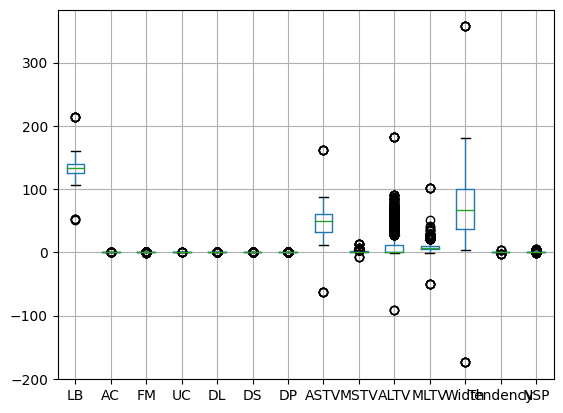

In [21]:
df.boxplot()

In [31]:
#### outlier capping

def outlier_capping(df,column):

    Q1= df[column].quantile(0.25)

    Q3= df[column].quantile(0.75)

    IQR= Q3-Q1

    lower_extreme= Q1-1.5*IQR

    upper_extreme= Q3+1.5*IQR

    df[column]= df[column].apply(lambda x: lower_extreme if x< lower_extreme else upper_extreme if x>upper_extreme else x)

for col in df.select_dtypes(include=['int','float']).columns:

    outlier_capping(df,col)

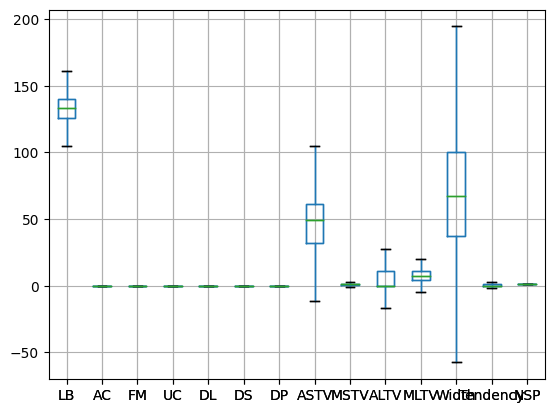

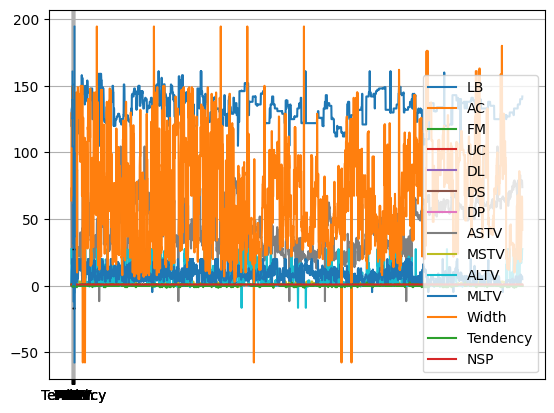

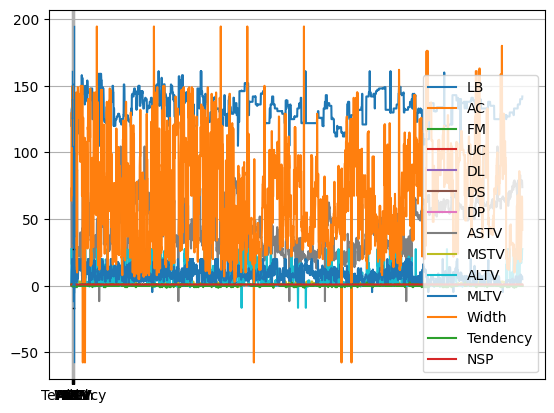

In [32]:
df.boxplot()
plt.show()

In [33]:
df.mean(numeric_only=True)

LB          133.288721
AC            0.003133
FM            0.001570
UC            0.004365
DL            0.001772
DS            0.000000
DP            0.000000
ASTV         46.998334
MSTV          1.304554
ALTV          6.697979
MLTV          8.002912
Width        70.323356
Tendency      0.316835
NSP           1.000000
dtype: float64

In [34]:
df.median(numeric_only=True)

LB          133.000000
AC            0.001634
FM            0.000000
UC            0.004486
DL            0.000000
DS            0.000000
DP            0.000000
ASTV         49.000000
MSTV          1.200000
ALTV          0.000000
MLTV          7.400000
Width        67.486468
Tendency      0.000000
NSP           1.000000
dtype: float64

In [39]:
df.std(numeric_only=True)

LB           9.926790
AC           0.003830
FM           0.002487
UC           0.003001
DL           0.002670
DS           0.000000
DP           0.000000
ASTV        17.609911
MSTV         0.781303
ALTV        10.381254
MLTV         5.046792
Width       39.577011
Tendency     0.622623
NSP          0.000000
dtype: float64

In [40]:
q1=df.quantile(0.25,numeric_only=True)
q3=df.quantile(0.75,numeric_only=True)
IQR=q3-q1
IQR

LB          14.000000
AC           0.005612
FM           0.002568
UC           0.004678
DL           0.003292
DS           0.000000
DP           0.000000
ASTV        29.000000
MSTV         1.000000
ALTV        11.000000
MLTV         6.200000
Width       63.000000
Tendency     1.000000
NSP          0.000000
dtype: float64

In [41]:
df.describe()


,LB,AC,FM,UC,DL,DS,DP,ASTV,MSTV,ALTV,MLTV,Width,Tendency,NSP
count,2124.000000,2124.000000,2124.000000,2124.000000,2124.000000,2124.0,2124.0,2124.000000,2124.000000,2124.000000,2124.000000,2124.000000,2124.000000,2124.0
mean,133.288721,0.003133,0.001570,0.004365,0.001772,0.0,0.0,46.998334,1.304554,6.697979,8.002912,70.323356,0.316835,1.0
std,9.926790,0.003830,0.002487,0.003001,0.002670,0.0,0.0,17.609911,0.781303,10.381254,5.046792,39.577011,0.622623,0.0
min,105.000000,-0.008418,-0.003853,-0.005158,-0.004938,0.0,0.0,-11.500000,-0.800000,-16.500000,-4.700000,-57.500000,-1.500000,1.0
25%,126.000000,0.000000,0.000000,0.001858,0.000000,0.0,0.0,32.000000,0.700000,0.000000,4.600000,37.000000,0.000000,1.0
50%,133.000000,0.001634,0.000000,0.004486,0.000000,0.0,0.0,49.000000,1.200000,0.000000,7.400000,67.486468,0.000000,1.0
75%,140.000000,0.005612,0.002568,0.006536,0.003292,0.0,0.0,61.000000,1.700000,11.000000,10.800000,100.000000,1.000000,1.0
max,161.000000,0.014030,0.006421,0.013552,0.008230,0.0,0.0,104.500000,3.200000,27.500000,20.100000,194.500000,2.500000,1.0


In [42]:
import matplotlib.pyplot as plt

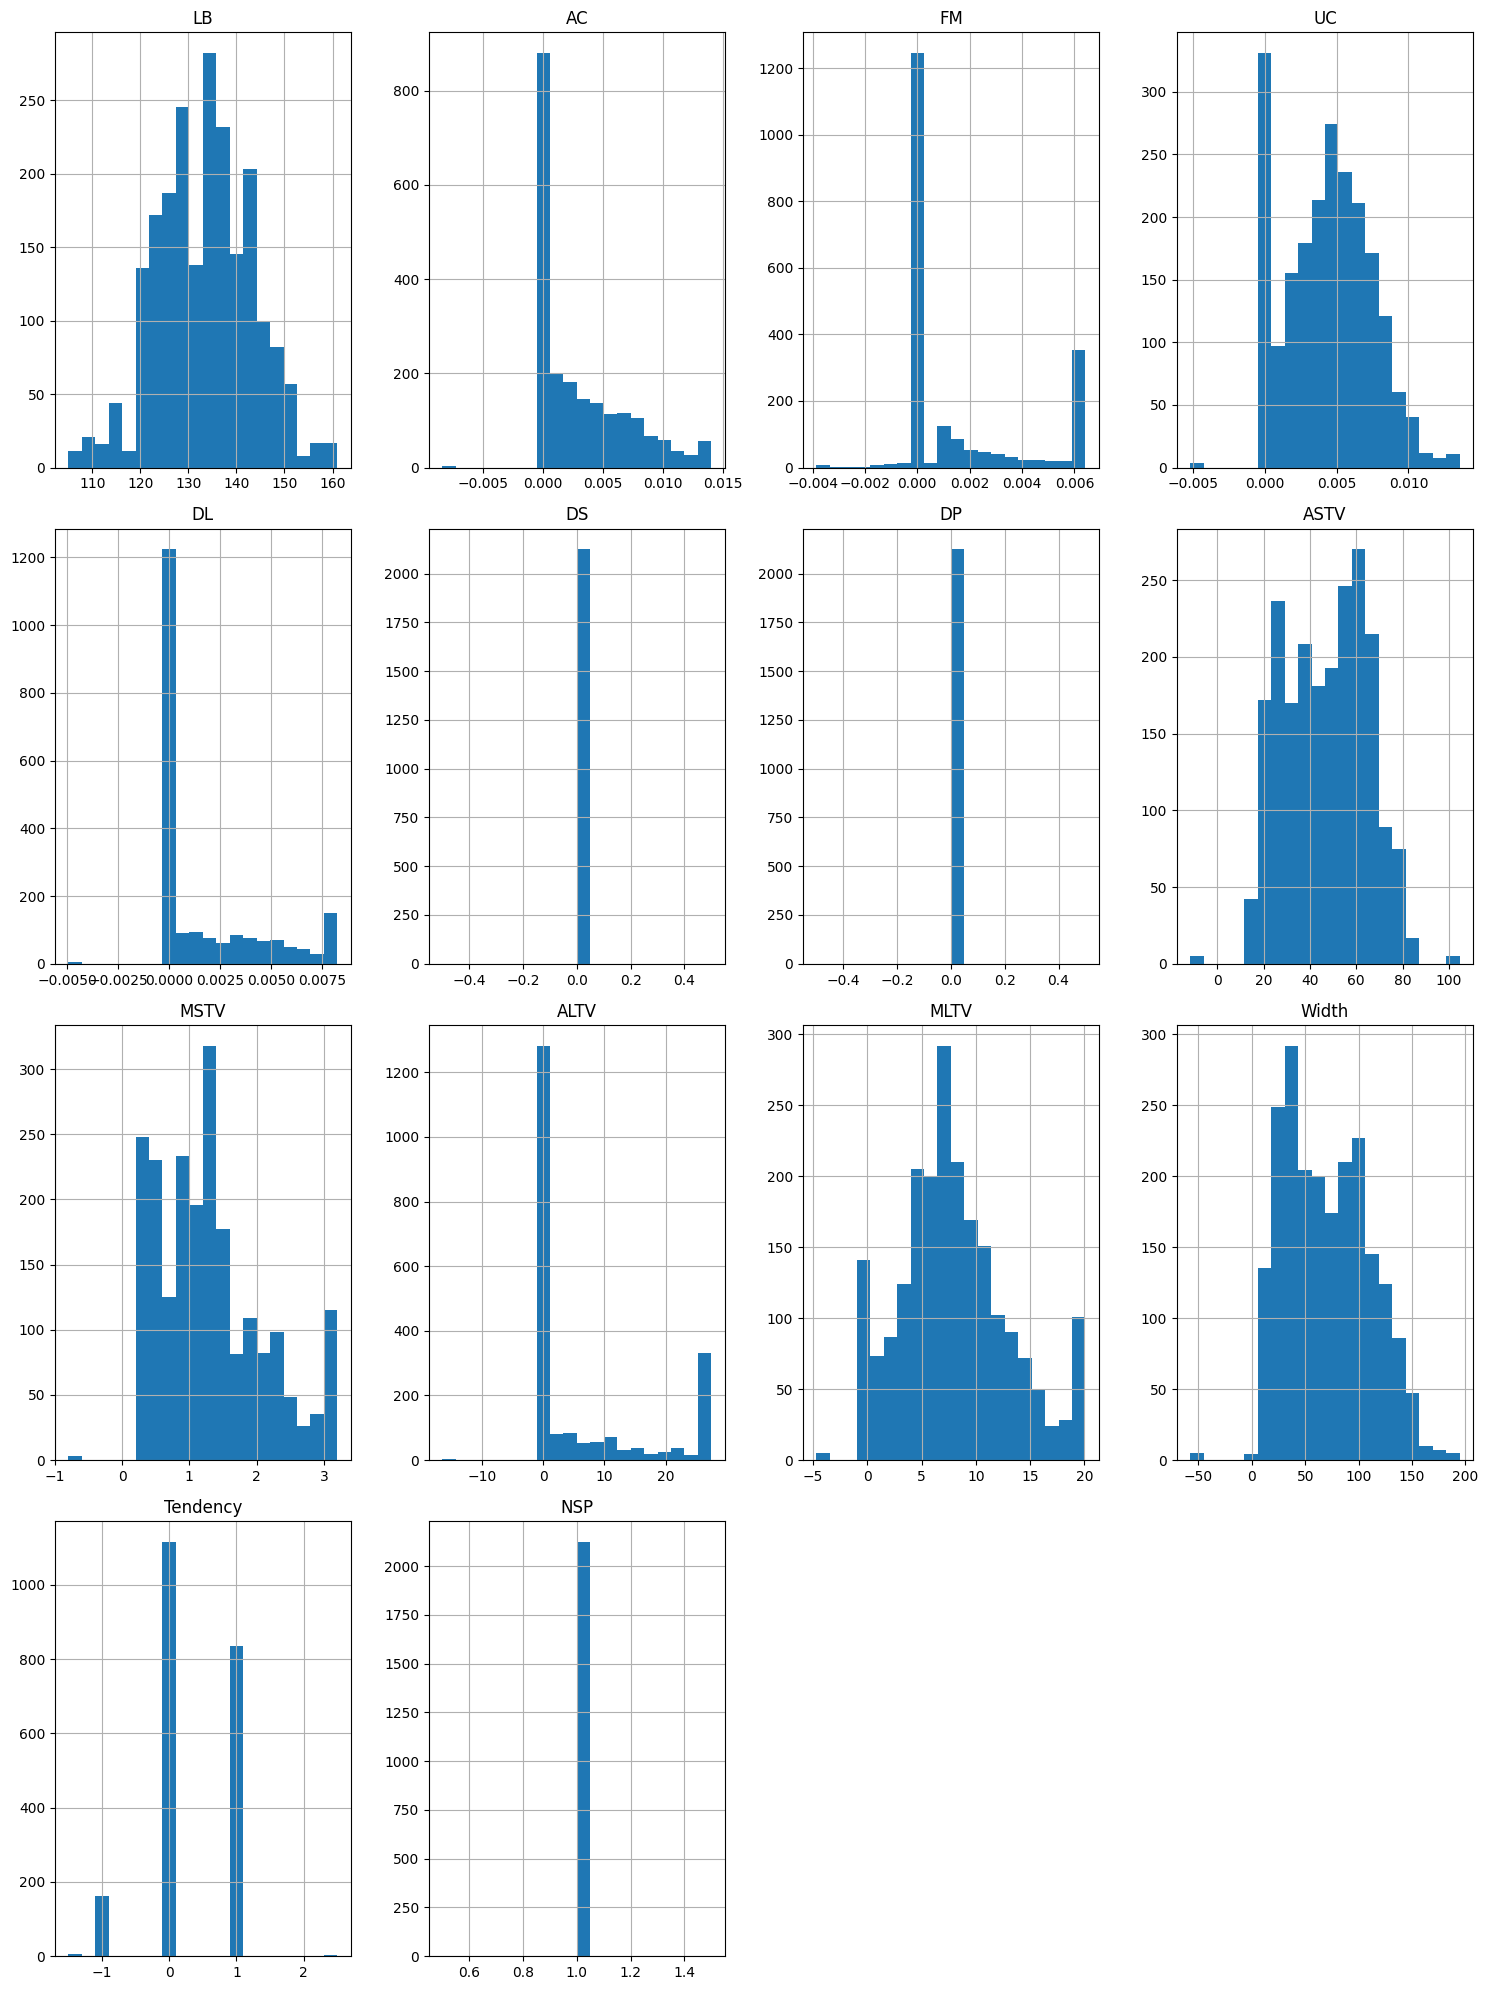

In [43]:
df.hist(figsize=(15,20),bins=20)
plt.tight_layout()
plt.show()

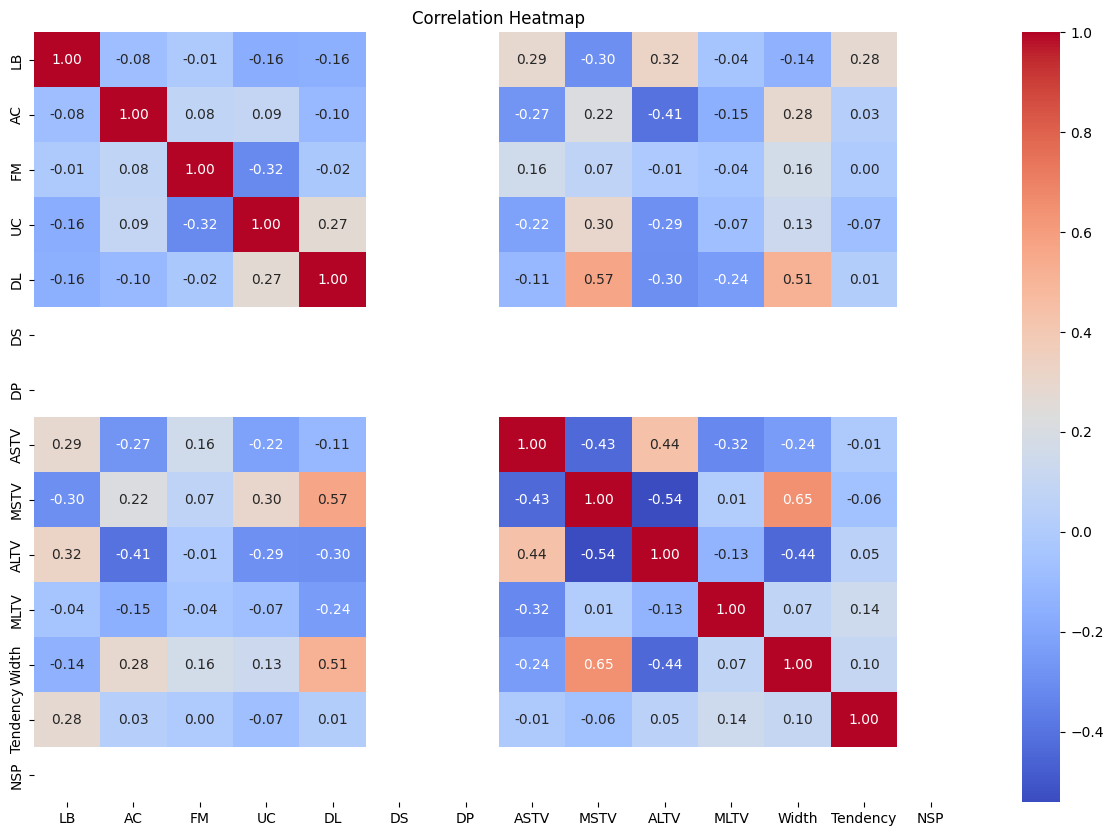

In [44]:
import seaborn as sns
import matplotlib.pyplot as plt
 
corr=df.corr()
plt.figure(figsize=(15,10))
sns.heatmap(corr,annot=True,cmap='coolwarm',fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

In [47]:
df.head()

,LB,AC,FM,UC,DL,DS,DP,ASTV,MSTV,ALTV,MLTV,Width,Tendency,NSP
0,120.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,73.0,0.5,27.5,2.4,64.0,0.999926,1.0
1,132.000000,0.006380,0.0,0.006380,0.003190,0.0,0.0,17.0,2.1,0.0,10.4,130.0,0.000000,1.0
2,133.000000,0.003322,0.0,0.008306,0.003322,0.0,0.0,16.0,2.1,0.0,13.4,130.0,0.000000,1.0
3,134.000000,0.002561,0.0,0.007742,0.002561,0.0,0.0,16.0,2.4,0.0,20.1,117.0,1.000000,1.0
4,131.948232,0.006515,0.0,0.008143,0.000000,0.0,0.0,16.0,2.4,0.0,19.9,117.0,1.000000,1.0


<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

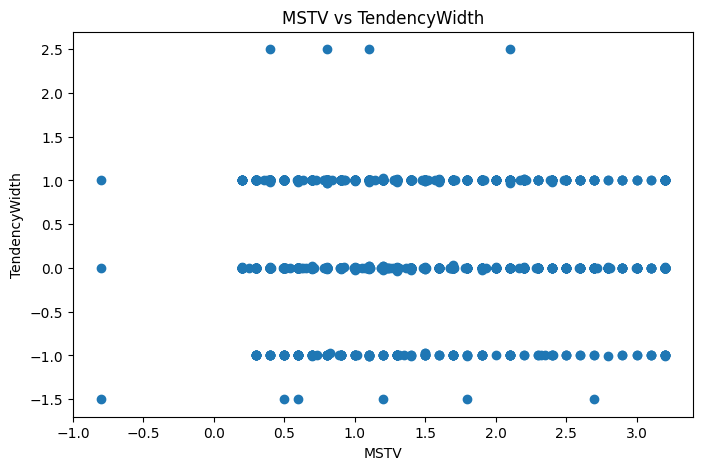

In [48]:
plt.figure(figsize=(8, 5))

plt.scatter(df['MSTV'], df['Tendency'])

plt.xlabel('MSTV')
plt.ylabel('TendencyWidth')
plt.title('MSTV vs TendencyWidth')

plt.show()

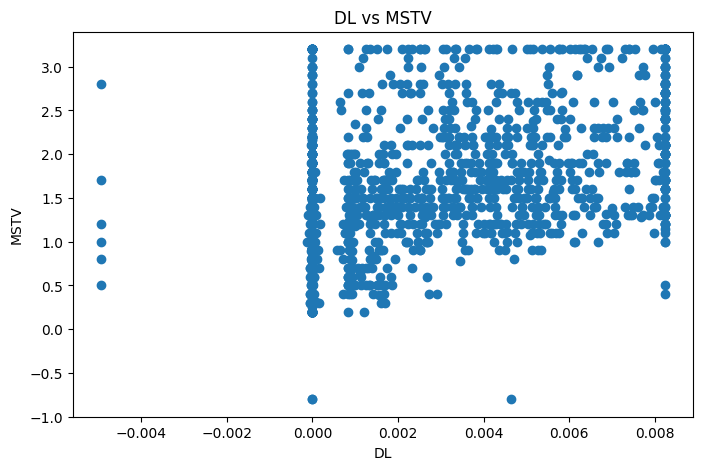

In [49]:
plt.figure(figsize=(8, 5))

plt.scatter(df['DL'], df['MSTV'])

plt.xlabel('DL')
plt.ylabel('MSTV')
plt.title('DL vs MSTV')

plt.show()

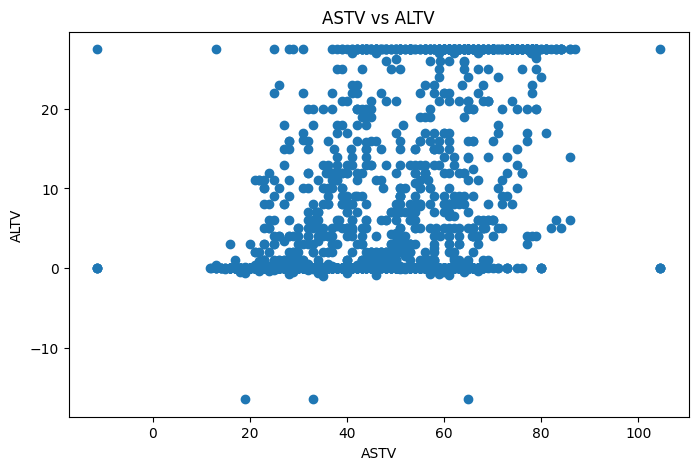

In [50]:
plt.figure(figsize=(8, 5))

plt.scatter(df['ASTV'], df['ALTV'])

plt.xlabel('ASTV')
plt.ylabel('ALTV')
plt.title('ASTV vs ALTV')

plt.show()

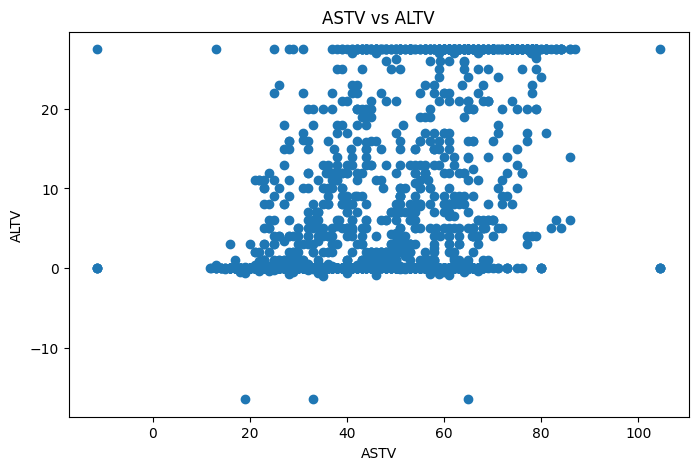

In [51]:
plt.figure(figsize=(8, 5))

plt.scatter(df['ASTV'], df['ALTV'])

plt.xlabel('ASTV')
plt.ylabel('ALTV')
plt.title('ASTV vs ALTV')

plt.show()

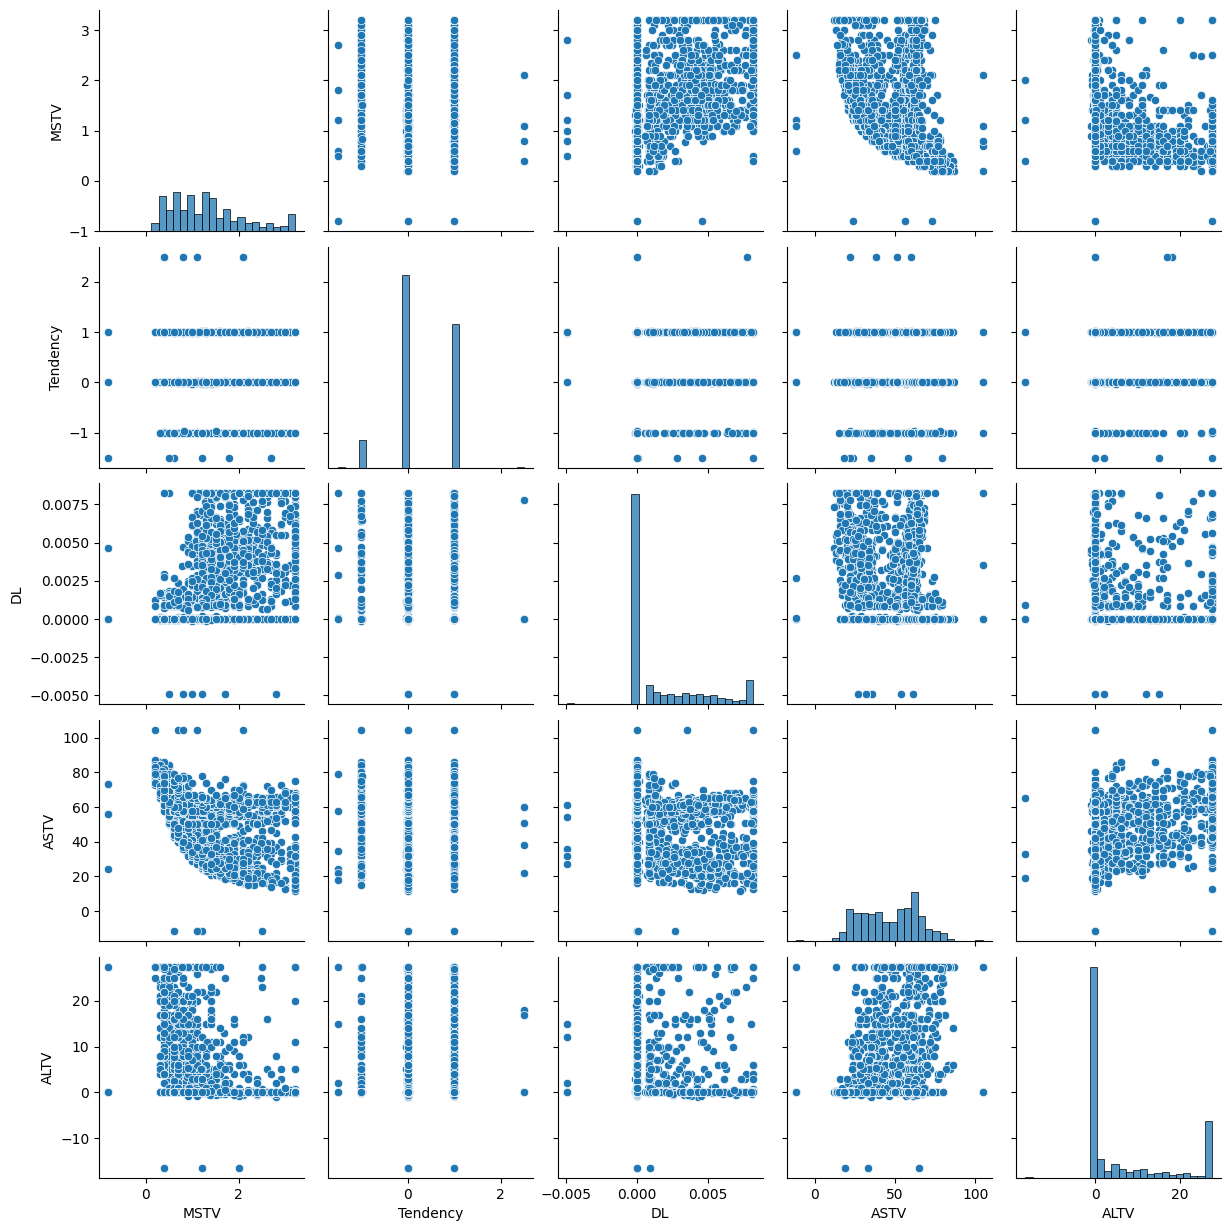

In [53]:
import seaborn as sns
import matplotlib.pyplot as plt

selected_columns = [
    'MSTV',
    'Tendency',
    'DL',
    'ASTV',
    'ALTV'
]

sns.pairplot(df[selected_columns])

plt.show()

In [55]:
correlation = df.corr()

corr_pairs = correlation.unstack()

corr_pairs = corr_pairs[
    (corr_pairs != 1) &
    (corr_pairs != -1)
]

corr_pairs.abs().sort_values(ascending=False).head(10)

MSTV   Width    0.646202
Width  MSTV     0.646202
DL     MSTV     0.566625
MSTV   DL       0.566625
       ALTV     0.541296
ALTV   MSTV     0.541296
Width  DL       0.514256
DL     Width    0.514256
ALTV   Width    0.439650
Width  ALTV     0.439650
dtype: float64

Conclusion:

The exploratory data analysis was performed on the cardiographic dataset.
The dataset was checked for missing values, duplicate records, data types,
and possible outliers. Statistical measures such as mean, median, standard
deviation, and IQR were calculated to understand the distribution of the
variables.

Histograms, boxplots, scatter plots, a correlation heatmap, and a pair plot
were used for visualization. The correlation analysis showed some moderate
relationships between variables, particularly between MSTV and TendencyWidth,
DL and MSTV, and DL and TendencyWidth. Several other variables showed weak
linear relationships.

These findings provide an initial understanding of the structure and
relationships within the dataset. Further analysis could investigate the
stronger relationships in more detail and explore their usefulness for
future predictive analysis.